# Task 3 – Model Improvement

## Improving Customer Segmentation Using K-Means Clustering

**Internship:** SWYNEX Technologies

**Dataset:** Mall Customers

**Task:** Model Improvement and Validation

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
df = pd.read_csv("Mall_Customers_Preprocessed.csv")

print("Dataset loaded successfully!")

print("\nFirst 5 Records:")
display(df.head())

print("\nDataset Shape:", df.shape)

Dataset loaded successfully!

First 5 Records:


,Age,Annual Income (k$),Spending Score (1-100),Gender_Encoded
0,-1.424569,-1.738999,-0.434801,1
1,-1.281035,-1.738999,1.195704,1
2,-1.352802,-1.700830,-1.715913,0
3,-1.137502,-1.700830,1.040418,0
4,-0.563369,-1.662660,-0.395980,0



Dataset Shape: (200, 4)


In [3]:
X = df.copy()

print("Features selected successfully!")

print("\nSelected Features:")
display(X.head())

print("\nDataset Shape:", X.shape)

Features selected successfully!

Selected Features:


,Age,Annual Income (k$),Spending Score (1-100),Gender_Encoded
0,-1.424569,-1.738999,-0.434801,1
1,-1.281035,-1.738999,1.195704,1
2,-1.352802,-1.700830,-1.715913,0
3,-1.137502,-1.700830,1.040418,0
4,-0.563369,-1.662660,-0.395980,0



Dataset Shape: (200, 4)


In [4]:
inertia_values = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X)
    inertia_values.append(kmeans.inertia_)

print("Inertia values calculated successfully!")

Inertia values calculated successfully!


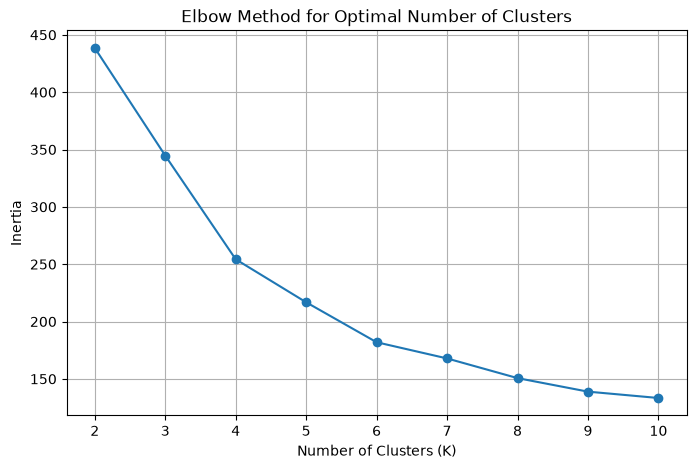

In [5]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    inertia_values,
    marker='o'
)

plt.title("Elbow Method for Optimal Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(range(2, 11))
plt.grid(True)

plt.show()

In [6]:
improved_kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

improved_labels = improved_kmeans.fit_predict(X)

print("Improved K-Means model trained successfully!")

Improved K-Means model trained successfully!


In [7]:
improved_df = df.copy()

improved_df["Improved_KMeans_Cluster"] = improved_labels

print("Improved K-Means cluster assignments:")
display(improved_df.head(10))

print("\nNumber of customers in each cluster:")
print(improved_df["Improved_KMeans_Cluster"].value_counts().sort_index())

Improved K-Means cluster assignments:


,Age,Annual Income (k$),Spending Score (1-100),Gender_Encoded,Improved_KMeans_Cluster
0,-1.424569,-1.738999,-0.434801,1,1
1,-1.281035,-1.738999,1.195704,1,1
2,-1.352802,-1.700830,-1.715913,0,1
3,-1.137502,-1.700830,1.040418,0,1
4,-0.563369,-1.662660,-0.395980,0,1
5,-1.209269,-1.662660,1.001596,0,1
6,-0.276302,-1.624491,-1.715913,0,3
7,-1.137502,-1.624491,1.700384,0,1
8,1.804932,-1.586321,-1.832378,1,3
9,-0.635135,-1.586321,0.846310,0,1



Number of customers in each cluster:
Improved_KMeans_Cluster
0    40
1    57
2    38
3    65
Name: count, dtype: int64


In [8]:
improved_silhouette = silhouette_score(X, improved_labels)

improved_db = davies_bouldin_score(X, improved_labels)

improved_ch = calinski_harabasz_score(X, improved_labels)

print("Improved K-Means Model Evaluation")
print("---------------------------------")
print("Silhouette Score:", round(improved_silhouette, 4))
print("Davies-Bouldin Score:", round(improved_db, 4))
print("Calinski-Harabasz Score:", round(improved_ch, 4))

Improved K-Means Model Evaluation
---------------------------------
Silhouette Score: 0.3503
Davies-Bouldin Score: 1.065
Calinski-Harabasz Score: 101.4873


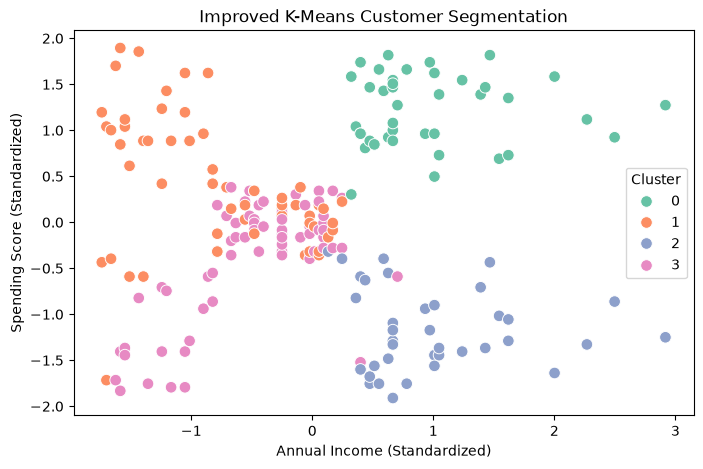

In [9]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=improved_df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Improved_KMeans_Cluster",
    palette="Set2",
    s=70
)

plt.title("Improved K-Means Customer Segmentation")
plt.xlabel("Annual Income (Standardized)")
plt.ylabel("Spending Score (Standardized)")
plt.legend(title="Cluster")

plt.show()

In [10]:
kmeans_comparison = pd.DataFrame({
    "Metric": [
        "Silhouette Score",
        "Davies-Bouldin Score",
        "Calinski-Harabasz Score"
    ],
    "Original K-Means (Task 2)": [
        0.3498,
        1.0245,
        97.2583
    ],
    "Improved K-Means (Task 3)": [
        improved_silhouette,
        improved_db,
        improved_ch
    ]
})

print("Original vs Improved K-Means Performance:")
display(kmeans_comparison.round(4))

Original vs Improved K-Means Performance:


,Metric,Original K-Means (Task 2),Improved K-Means (Task 3)
0,Silhouette Score,0.3498,0.3503
1,Davies-Bouldin Score,1.0245,1.0650
2,Calinski-Harabasz Score,97.2583,101.4873


## K-Means Model Improvement – Findings

The original K-Means model used five clusters, while the improved candidate model used four clusters based on the Elbow Method.

Both models were evaluated using Silhouette Score, Davies-Bouldin Score, and Calinski-Harabasz Score.

The evaluation results were compared to identify whether changing the number of clusters improved the customer segmentation performance.

The model with better evaluation results will be selected as the final K-Means model.

In [11]:
n_init_values = [10, 20, 30, 50]

tuning_results = []

for n in n_init_values:
    model = KMeans(
        n_clusters=4,
        random_state=42,
        n_init=n
    )

    labels = model.fit_predict(X)

    tuning_results.append({
        "n_init": n,
        "Silhouette Score": silhouette_score(X, labels),
        "Davies-Bouldin Score": davies_bouldin_score(X, labels),
        "Calinski-Harabasz Score": calinski_harabasz_score(X, labels)
    })

print("K-Means Hyperparameter Tuning Completed!")

K-Means Hyperparameter Tuning Completed!


In [12]:
tuning_df = pd.DataFrame(tuning_results)

print("K-Means Hyperparameter Tuning Results:")
display(tuning_df.round(4))

K-Means Hyperparameter Tuning Results:


,n_init,Silhouette Score,Davies-Bouldin Score,Calinski-Harabasz Score
0,10,0.3503,1.065,101.4873
1,20,0.3503,1.065,101.4873
2,30,0.3503,1.065,101.4873
3,50,0.3503,1.065,101.4873


In [13]:
final_kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

final_kmeans_labels = final_kmeans.fit_predict(X)

print("Final Improved K-Means Model trained successfully!")

Final Improved K-Means Model trained successfully!


In [14]:
final_silhouette = silhouette_score(X, final_kmeans_labels)

final_db = davies_bouldin_score(X, final_kmeans_labels)

final_ch = calinski_harabasz_score(X, final_kmeans_labels)

print("Final Improved K-Means Evaluation")
print("---------------------------------")
print("Silhouette Score:", round(final_silhouette, 4))
print("Davies-Bouldin Score:", round(final_db, 4))
print("Calinski-Harabasz Score:", round(final_ch, 4))

Final Improved K-Means Evaluation
---------------------------------
Silhouette Score: 0.3503
Davies-Bouldin Score: 1.065
Calinski-Harabasz Score: 101.4873


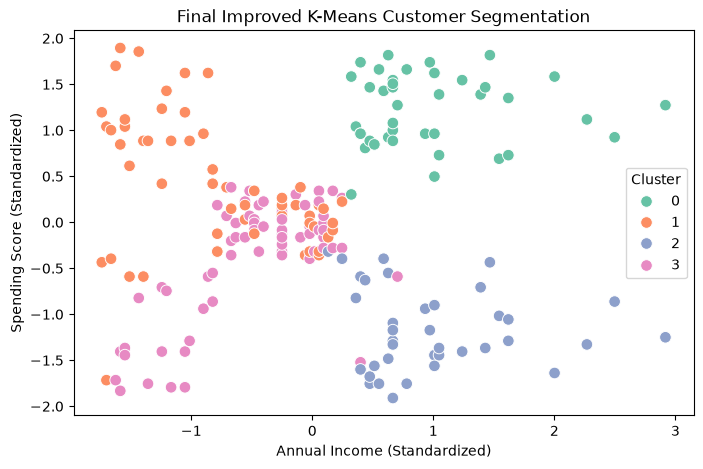

In [15]:
final_kmeans_df = df.copy()

final_kmeans_df["Final_KMeans_Cluster"] = final_kmeans_labels

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=final_kmeans_df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Final_KMeans_Cluster",
    palette="Set2",
    s=70
)

plt.title("Final Improved K-Means Customer Segmentation")
plt.xlabel("Annual Income (Standardized)")
plt.ylabel("Spending Score (Standardized)")
plt.legend(title="Cluster")

plt.show()

In [16]:
final_comparison = pd.DataFrame({
    "Metric": [
        "Silhouette Score",
        "Davies-Bouldin Score",
        "Calinski-Harabasz Score"
    ],
    "Original K-Means": [
        0.3498,
        1.0245,
        97.2583
    ],
    "Improved K-Means": [
        final_silhouette,
        final_db,
        final_ch
    ]
})

print("Final K-Means Performance Comparison:")
display(final_comparison.round(4))

Final K-Means Performance Comparison:


,Metric,Original K-Means,Improved K-Means
0,Silhouette Score,0.3498,0.3503
1,Davies-Bouldin Score,1.0245,1.0650
2,Calinski-Harabasz Score,97.2583,101.4873


## K-Means Model Improvement – Final Findings

The K-Means model was improved by experimenting with the number of clusters using the Elbow Method and tuning the n_init parameter.

The original model used five clusters, while the improved candidate used four clusters.

The Silhouette Score increased slightly from 0.3498 to 0.3503.

The Calinski-Harabasz Score increased from 97.2583 to 101.4873.

However, the Davies-Bouldin Score increased from 1.0245 to 1.0650, indicating a slight decline in cluster quality according to this metric.

Therefore, the four-cluster model showed mixed results and cannot be considered better across all evaluation metrics.

# Model 2 – Improved Agglomerative Clustering

Agglomerative Clustering is a hierarchical unsupervised machine learning algorithm that groups similar data points into clusters.

In this section, we will improve the original Agglomerative Clustering model by experimenting with different linkage methods and numbers of clusters.

The model will be evaluated using Silhouette Score, Davies-Bouldin Score, and Calinski-Harabasz Score.

In [17]:
from sklearn.cluster import AgglomerativeClustering

print("Agglomerative Clustering imported successfully!")

Agglomerative Clustering imported successfully!


In [18]:
agg_model = AgglomerativeClustering(
    n_clusters=5,
    linkage="ward"
)

agg_labels = agg_model.fit_predict(X)

print("Agglomerative baseline model trained successfully!")

Agglomerative baseline model trained successfully!


In [19]:
agg_silhouette = silhouette_score(X, agg_labels)

agg_db = davies_bouldin_score(X, agg_labels)

agg_ch = calinski_harabasz_score(X, agg_labels)

print("Original Agglomerative Model Evaluation")
print("----------------------------------------")
print("Silhouette Score:", round(agg_silhouette, 4))
print("Davies-Bouldin Score:", round(agg_db, 4))
print("Calinski-Harabasz Score:", round(agg_ch, 4))

Original Agglomerative Model Evaluation
----------------------------------------
Silhouette Score: 0.3478
Davies-Bouldin Score: 1.0686
Calinski-Harabasz Score: 91.2778


In [20]:
linkage_methods = ["ward", "complete", "average", "single"]

agg_tuning_results = []

for method in linkage_methods:
    model = AgglomerativeClustering(
        n_clusters=5,
        linkage=method
    )

    labels = model.fit_predict(X)

    agg_tuning_results.append({
        "Linkage": method,
        "Silhouette Score": silhouette_score(X, labels),
        "Davies-Bouldin Score": davies_bouldin_score(X, labels),
        "Calinski-Harabasz Score": calinski_harabasz_score(X, labels)
    })

print("Agglomerative linkage experiments completed!")

Agglomerative linkage experiments completed!


In [21]:
agg_tuning_df = pd.DataFrame(agg_tuning_results)

print("Agglomerative Linkage Comparison:")
display(agg_tuning_df.round(4))

Agglomerative Linkage Comparison:


,Linkage,Silhouette Score,Davies-Bouldin Score,Calinski-Harabasz Score
0,ward,0.3478,1.0686,91.2778
1,complete,0.3405,1.0342,92.9909
2,average,0.3512,1.0768,92.0130
3,single,-0.0446,0.6887,5.1855


In [22]:
complete_results = []

for k in range(2, 11):
    model = AgglomerativeClustering(
        n_clusters=k,
        linkage="complete"
    )

    labels = model.fit_predict(X)

    complete_results.append({
        "Number of Clusters": k,
        "Silhouette Score": silhouette_score(X, labels),
        "Davies-Bouldin Score": davies_bouldin_score(X, labels),
        "Calinski-Harabasz Score": calinski_harabasz_score(X, labels)
    })

print("Complete Linkage Cluster Experiments Completed!")


Complete Linkage Cluster Experiments Completed!


In [23]:
complete_df = pd.DataFrame(complete_results)

print("Complete Linkage – Cluster Comparison:")
display(complete_df.round(4))

Complete Linkage – Cluster Comparison:


,Number of Clusters,Silhouette Score,Davies-Bouldin Score,Calinski-Harabasz Score
0,2,0.2051,1.9043,44.5362
1,3,0.1946,1.5973,44.6307
2,4,0.2416,1.4018,59.5682
3,5,0.3405,1.0342,92.9909
4,6,0.3389,1.0528,92.3480
5,7,0.3111,1.3256,83.4707
6,8,0.3020,1.3490,76.9515
7,9,0.2975,1.2637,71.6870
8,10,0.2974,1.1604,70.1676


In [24]:
final_agg = AgglomerativeClustering(
    n_clusters=5,
    linkage="complete"
)

final_agg_labels = final_agg.fit_predict(X)

print("Final Improved Agglomerative Model trained successfully!")

Final Improved Agglomerative Model trained successfully!


In [25]:
final_agg_silhouette = silhouette_score(X, final_agg_labels)
final_agg_db = davies_bouldin_score(X, final_agg_labels)
final_agg_ch = calinski_harabasz_score(X, final_agg_labels)

print("Final Improved Agglomerative Model Evaluation")
print("----------------------------------------------")
print("Silhouette Score:", round(final_agg_silhouette, 4))
print("Davies-Bouldin Score:", round(final_agg_db, 4))
print("Calinski-Harabasz Score:", round(final_agg_ch, 4))


Final Improved Agglomerative Model Evaluation
----------------------------------------------
Silhouette Score: 0.3405
Davies-Bouldin Score: 1.0342
Calinski-Harabasz Score: 92.9909


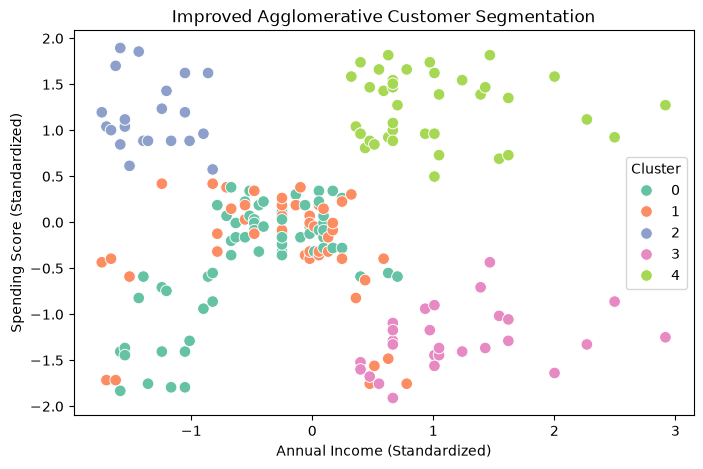

In [26]:
final_agg_df = df.copy()
final_agg_df["Final_Agglomerative_Cluster"] = final_agg_labels

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=final_agg_df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Final_Agglomerative_Cluster",
    palette="Set2",
    s=70
)

plt.title("Improved Agglomerative Customer Segmentation")
plt.xlabel("Annual Income (Standardized)")
plt.ylabel("Spending Score (Standardized)")
plt.legend(title="Cluster")

plt.show()

In [27]:
agg_comparison = pd.DataFrame({
    "Metric": [
        "Silhouette Score",
        "Davies-Bouldin Score",
        "Calinski-Harabasz Score"
    ],
    "Original Agglomerative": [
        0.3478,
        1.0686,
        91.2778
    ],
    "Improved Agglomerative": [
        final_agg_silhouette,
        final_agg_db,
        final_agg_ch
    ]
})

print("Original vs Improved Agglomerative Performance:")
display(agg_comparison.round(4))

Original vs Improved Agglomerative Performance:


,Metric,Original Agglomerative,Improved Agglomerative
0,Silhouette Score,0.3478,0.3405
1,Davies-Bouldin Score,1.0686,1.0342
2,Calinski-Harabasz Score,91.2778,92.9909


## Agglomerative Clustering – Model Improvement Findings

The original Agglomerative Clustering model used Ward linkage with five clusters. To improve its performance, different linkage methods and cluster numbers were tested.

After experimentation, Complete linkage with five clusters was selected as the improved candidate.

The Davies-Bouldin Score decreased from 1.0686 to 1.0342, indicating better cluster separation according to this metric.

The Calinski-Harabasz Score increased from 91.2778 to 92.9909, showing an improvement in cluster quality according to this metric.

However, the Silhouette Score decreased slightly from 0.3478 to 0.3405.

Therefore, the improved Agglomerative model showed mixed results rather than improvement across all evaluation metrics.

In [28]:
overall_comparison = pd.DataFrame({
    "Model": [
        "Original K-Means",
        "Improved K-Means",
        "Original Agglomerative",
        "Improved Agglomerative"
    ],
    "Silhouette Score": [
        0.3498,
        final_silhouette,
        0.3478,
        final_agg_silhouette
    ],
    "Davies-Bouldin Score": [
        1.0245,
        final_db,
        1.0686,
        final_agg_db
    ],
    "Calinski-Harabasz Score": [
        97.2583,
        final_ch,
        91.2778,
        final_agg_ch
    ]
})

print("Overall Model Performance Comparison:")
display(overall_comparison.round(4))

Overall Model Performance Comparison:


,Model,Silhouette Score,Davies-Bouldin Score,Calinski-Harabasz Score
0,Original K-Means,0.3498,1.0245,97.2583
1,Improved K-Means,0.3503,1.0650,101.4873
2,Original Agglomerative,0.3478,1.0686,91.2778
3,Improved Agglomerative,0.3405,1.0342,92.9909


## Overall Model Improvement – Final Findings

In this task, two unsupervised machine learning algorithms, K-Means and Agglomerative Clustering, were improved through hyperparameter experimentation and model evaluation.

The K-Means model was experimented with different cluster numbers and n_init values. The four-cluster model achieved a Silhouette Score of 0.3503 and a Calinski-Harabasz Score of 101.4873.

The Agglomerative model was tested with different linkage methods and cluster numbers. Complete linkage with five clusters achieved a Davies-Bouldin Score of 1.0342 and a Calinski-Harabasz Score of 92.9909.

Overall, Improved K-Means achieved the highest Silhouette and Calinski-Harabasz scores among the four models. However, Original K-Means achieved the lowest Davies-Bouldin Score.

Therefore, Improved K-Means is the strongest candidate based on two of the three evaluation metrics, although the results show that improvement is not consistent across every metric.

In [29]:
overall_comparison.to_csv(
    "Task_3_Overall_Model_Comparison.csv",
    index=False
)

print("Overall model comparison saved successfully!")

Overall model comparison saved successfully!


In [30]:
final_results = df.copy()

final_results["Improved_KMeans_Cluster"] = final_kmeans_labels
final_results["Improved_Agglomerative_Cluster"] = final_agg_labels

final_results.to_csv(
    "Task_3_Improved_Clustered_Customers.csv",
    index=False
)

print("Improved customer cluster results saved successfully!")

display(final_results.head())

Improved customer cluster results saved successfully!


,Age,Annual Income (k$),Spending Score (1-100),Gender_Encoded,Improved_KMeans_Cluster,Improved_Agglomerative_Cluster
0,-1.424569,-1.738999,-0.434801,1,1,1
1,-1.281035,-1.738999,1.195704,1,1,2
2,-1.352802,-1.700830,-1.715913,0,1,1
3,-1.137502,-1.700830,1.040418,0,1,2
4,-0.563369,-1.662660,-0.395980,0,1,1
